# Brain Tumour Classification with MRI Image Data

##### Course: Deep Learning
##### Team: Group 02 - (Apurva Lawate and Rijvi Kulkarni)

# 1. Essentials

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# %cd drive/MyDrive/PATH/TO/FOLDER
%cd /content/drive/MyDrive/DeepLearning

/content/drive/MyDrive/DeepLearning


In [ ]:
# Management of files
import os
from os.path import exists, join

# Tensorflow and Keras
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping
from tensorflow.keras.models import Model, load_model
from tensorflow.keras.layers import Dense, Flatten, Input, Lambda, Dropout, GlobalAveragePooling2D, BatchNormalization, Activation
from tensorflow.keras.optimizers import Adam, Adamax
from tensorflow.keras.applications.resnet50 import ResNet50, preprocess_input
from tensorflow.keras.metrics import Precision, Recall
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications import VGG16

#sklearn
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

# Albumentations for data augmentation
from albumentations import Blur, \
                           Compose, \
                           HorizontalFlip, \
                           RandomBrightnessContrast, \
                           RandomRotate90, \
                           VerticalFlip

# Reading images
import tifffile
import cv2

# Working with arrays
import numpy as np
import json

# Visualization
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns

# External files with functions to load the dataset,
# create a CNN model, and a data generator.
from importlib import reload
import datasets
import data_generator_fine_tune
import gradcam
# Useful to reload modified external files without need
# of restarting the kernel. Just run again this cell.
reload(datasets)
reload(data_generator_fine_tune)
reload(gradcam)

from datasets import *
from data_generator_fine_tune import *
from gradcam import *

In [ ]:
PROJECT_DIR = "." # os.getcwd()
SEED = 42
BATCH_SIZE = 32
TARGET_SIZE = 256
EPOCHS = 200

# 2. Data

## 2.1 Loading

In [ ]:
PROJECT_DIR = "."
# setting up the path leading to dataset folder
path_data_class = os.path.join(PROJECT_DIR,
                       "Brain_Tumour_Data",
                       "Dataset")

In [ ]:
# This function will print a tree structure given a Google Drive's path for the dataset

def print_tree(path, prefix=''):

    items = sorted(os.listdir(path))

    jpg_count = 0
    for item in items:
        item_path = os.path.join(path, item)
        if os.path.isdir(item_path):
            print(f"{prefix}+--- {item}")
            print_tree(item_path, prefix + "|   ")
            jpg_count = 0  # reset for new folder
        elif item.lower().endswith('.jpg') and jpg_count < 2:
            print(f"{prefix}+--- {item}")
            jpg_count += 1

print_tree(path_data_class)

+--- Testing
|   +--- glioma
|   |   +--- Te-glTr_0000.jpg
|   |   +--- Te-glTr_0001.jpg
|   +--- meningioma
|   |   +--- Te-meTr_0000.jpg
|   |   +--- Te-meTr_0001.jpg
|   +--- notumor
|   |   +--- Te-noTr_0000.jpg
|   |   +--- Te-noTr_0001.jpg
|   +--- pituitary
|   |   +--- Te-piTr_0000.jpg
|   |   +--- Te-piTr_0001.jpg
+--- Training
|   +--- glioma
|   |   +--- Tr-glTr_0000.jpg
|   |   +--- Tr-glTr_0001.jpg
|   +--- meningioma
|   |   +--- Tr-meTr_0000.jpg
|   |   +--- Tr-meTr_0001.jpg
|   +--- notumor
|   |   +--- Tr-noTr_0000.jpg
|   |   +--- Tr-noTr_0001.jpg
|   +--- pituitary
|   |   +--- Tr-piTr_0000.jpg
|   |   +--- Tr-piTr_0001.jpg


In [ ]:
# Load and sort image paths
train_image_paths = natsorted(glob(os.path.join(path_data_class, "Training", "**", "*.jpg"), recursive=True), key=lambda x: x.lower())
test_image_paths = natsorted(glob(os.path.join(path_data_class, "Testing", "**", "*.jpg"), recursive=True), key=lambda x: x.lower())

## 2.2 Training Data

In [ ]:
# DataFrame for training data
train_df_class = pd.DataFrame(train_image_paths, columns=["path_image"])
train_df_class["class_str"] = train_df_class["path_image"].apply(lambda x: x.split("/")[-2])
train_classes = np.unique(train_df_class["class_str"])

train_class_dict = {cls: idx for idx, cls in enumerate(train_classes)}
train_df_class["class_int"] = train_df_class["class_str"].map(train_class_dict)

train_df_class

,path_image,class_str,class_int
0,./Brain_Tumour_Data/Dataset/Training/glioma/Tr...,glioma,0
1,./Brain_Tumour_Data/Dataset/Training/glioma/Tr...,glioma,0
2,./Brain_Tumour_Data/Dataset/Training/glioma/Tr...,glioma,0
3,./Brain_Tumour_Data/Dataset/Training/glioma/Tr...,glioma,0
4,./Brain_Tumour_Data/Dataset/Training/glioma/Tr...,glioma,0
...,...,...,...
5707,./Brain_Tumour_Data/Dataset/Training/pituitary...,pituitary,3
5708,./Brain_Tumour_Data/Dataset/Training/pituitary...,pituitary,3
5709,./Brain_Tumour_Data/Dataset/Training/pituitary...,pituitary,3
5710,./Brain_Tumour_Data/Dataset/Training/pituitary...,pituitary,3


## 2.3 Validation and Testing Data

In [ ]:
classes = np.unique(train_df_class["class_str"].values)
classes_int = np.arange(len(classes))
classes_dict = dict(zip(classes, classes_int))
n_classes = len(classes)

In [ ]:
# DataFrame for testing data
test_df_class = pd.DataFrame(test_image_paths, columns=["path_image"])
test_df_class["class_str"] = test_df_class["path_image"].apply(lambda x: x.split("/")[-2])
test_classes = np.unique(test_df_class["class_str"])

test_class_dict = {cls: idx for idx, cls in enumerate(test_classes)}
test_df_class["class_int"] = test_df_class["class_str"].map(test_class_dict)

test_df_class

,path_image,class_str,class_int
0,./Brain_Tumour_Data/Dataset/Testing/glioma/Te-...,glioma,0
1,./Brain_Tumour_Data/Dataset/Testing/glioma/Te-...,glioma,0
2,./Brain_Tumour_Data/Dataset/Testing/glioma/Te-...,glioma,0
3,./Brain_Tumour_Data/Dataset/Testing/glioma/Te-...,glioma,0
4,./Brain_Tumour_Data/Dataset/Testing/glioma/Te-...,glioma,0
...,...,...,...
1306,./Brain_Tumour_Data/Dataset/Testing/pituitary/...,pituitary,3
1307,./Brain_Tumour_Data/Dataset/Testing/pituitary/...,pituitary,3
1308,./Brain_Tumour_Data/Dataset/Testing/pituitary/...,pituitary,3
1309,./Brain_Tumour_Data/Dataset/Testing/pituitary/...,pituitary,3


In [ ]:
valid_df_class, test_df_class = train_test_split(test_df_class, train_size=0.5, random_state=20, stratify=test_df_class['class_str'])
valid_df_class

,path_image,class_str,class_int
286,./Brain_Tumour_Data/Dataset/Testing/glioma/Te-...,glioma,0
318,./Brain_Tumour_Data/Dataset/Testing/meningioma...,meningioma,1
1072,./Brain_Tumour_Data/Dataset/Testing/pituitary/...,pituitary,3
373,./Brain_Tumour_Data/Dataset/Testing/meningioma...,meningioma,1
109,./Brain_Tumour_Data/Dataset/Testing/glioma/Te-...,glioma,0
...,...,...,...
59,./Brain_Tumour_Data/Dataset/Testing/glioma/Te-...,glioma,0
860,./Brain_Tumour_Data/Dataset/Testing/notumor/Te...,notumor,2
273,./Brain_Tumour_Data/Dataset/Testing/glioma/Te-...,glioma,0
494,./Brain_Tumour_Data/Dataset/Testing/meningioma...,meningioma,1


In [ ]:
test_df_class


,path_image,class_str,class_int
566,./Brain_Tumour_Data/Dataset/Testing/meningioma...,meningioma,1
158,./Brain_Tumour_Data/Dataset/Testing/glioma/Te-...,glioma,0
483,./Brain_Tumour_Data/Dataset/Testing/meningioma...,meningioma,1
800,./Brain_Tumour_Data/Dataset/Testing/notumor/Te...,notumor,2
916,./Brain_Tumour_Data/Dataset/Testing/notumor/Te...,notumor,2
...,...,...,...
671,./Brain_Tumour_Data/Dataset/Testing/notumor/Te...,notumor,2
271,./Brain_Tumour_Data/Dataset/Testing/glioma/Te-...,glioma,0
545,./Brain_Tumour_Data/Dataset/Testing/meningioma...,meningioma,1
322,./Brain_Tumour_Data/Dataset/Testing/meningioma...,meningioma,1


In [ ]:
splits = {
    "x_train": train_df_class["path_image"].values,
    "y_train": train_df_class["class_int"].values,
    "x_val": valid_df_class["path_image"].values,
    "y_val": valid_df_class["class_int"].values,
    "x_test": test_df_class["path_image"].values,
    "y_test": test_df_class["class_int"].values
}

x_train = splits["x_train"]
y_train = splits["y_train"]
x_val = splits["x_val"]
y_val = splits["y_val"]
x_test = splits["x_test"]
y_test = splits["y_test"]

## 2.4 Augmentation

In [ ]:
def augmentation():
  return Compose([
                  RandomBrightnessContrast(p=0.5),
                  ], p = 1)

In [ ]:
data_gen_train = DataGenerator(path_images=x_train,
                               labels=y_train,
                               batch_size=BATCH_SIZE,
                               n_classes=n_classes,
                               target_size=TARGET_SIZE,
                               augmentation=augmentation,
                               preprocess_input=preprocess_input,
                               shuffle=True)

data_gen_val = DataGenerator(path_images=x_val,
                             labels=y_val,
                             batch_size=BATCH_SIZE,
                             n_classes=n_classes,
                             target_size=TARGET_SIZE,
                             preprocess_input=preprocess_input,
                             shuffle=False)

# 3. GradCam

In [ ]:
class PlotGradCAM(keras.callbacks.Callback):
  def __init__(self, data, n_images=3):
    super().__init__()
    self.data = data
    self.n_images = n_images

  def on_epoch_end(self, epoch, logs=None):
    plt.figure(figsize=(15,30))
    for i in range(self.n_images):
      # input data
      x = self.data[0][i]
      x_orig = x.astype(np.uint8)
      x = np.expand_dims(x, axis=0)
      # reference class
      y = np.argmax(self.data[1][i])
      # predicted class
      y_pred = self.model.predict(x,verbose=0)
      id_class_pred = np.argmax(y_pred[0])
      str_class_pred = list(classes_dict.keys())[id_class_pred]
      str_class_ref = list(classes_dict.keys())[y]
      # compute GradCAM
      cam = GradCAM(self.model, id_class_pred)
      heatmap = cam.compute_heatmap(x)
      (heatmap, output) = cam.overlay_heatmap(heatmap, x_orig, alpha=0.5)
      # show the first self.n_images in a batch
      plt.subplot(1,self.n_images,i+1)
      plt.imshow(output)
      plt.title("R:{}\nP:{}".format(str_class_ref, str_class_pred), fontsize=8)
      plt.axis("off")
    plt.show()

# 4. ResNet-50

## 4.1 Model Definition

In [ ]:
def get_resnet_model(n_classes, input_shape):

    base_model = ResNet50(include_top=False,
                          weights="imagenet",
                          input_shape=input_shape,
                          pooling='max')
    base_model.trainable = False

    x = base_model.output
    x = Flatten()(x)
    x = Dropout(rate=0.3)(x)
    x = Dense(128, activation='relu')(x)
    x = Dropout(rate=0.25)(x)
    output = Dense(n_classes, activation='softmax')(x)

    model = Model(inputs=base_model.input, outputs=output)


    model.compile(optimizer=Adamax(learning_rate=0.001),
                  loss='categorical_crossentropy',
                  metrics=['accuracy', Precision(), Recall()])

    return model

In [ ]:
resnet_model = get_resnet_model(n_classes=n_classes,
                                input_shape=(TARGET_SIZE, TARGET_SIZE, 3))

resnet_model.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 262, 262,  │          0 │ input_layer[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 128, 128,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 128, 128,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 128, 128,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 130, 130,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 64, 64,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 64, 64,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 64, 64,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 64, 64,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 64, 64,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 64, 64,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 64, 64,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 64, 64,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 64, 64,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 64, 64,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 64, 64,    │      1,024 │ conv2_block1_3_c

 Total params: 23,850,500 (90.98 MB)

 Trainable params: 262,788 (1.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [ ]:
# Callbacks

# Checkpoints
autosave = ModelCheckpoint("resnet_model.keras",
                           mode="max",
                           save_best_only=True,
                           monitor="val_accuracy",
                           verbose=1)

# Early stopping
early_stop = EarlyStopping(patience=20,
                           verbose=1,
                           mode="max",
                           monitor="val_accuracy",
                           restore_best_weights=True)

# Change the index of the data generator to visualize other batch during training
cbks = [autosave,
        early_stop,
        PlotGradCAM(data=data_gen_train[1],
                    n_images=9)
        ]

## 4.2 Model Training

In [ ]:
MODEL_PATH = "resnet_model.keras"
HISTORY_PATH = "resnet50_history.json"

if os.path.exists(MODEL_PATH) and os.path.exists(HISTORY_PATH):
    print("Loading ResNet50 model and training history from drive: ")
    resnet_model = load_model(MODEL_PATH)

    with open(HISTORY_PATH, "r") as f:
        history_dict = json.load(f)

    # Dummy object to mimic Keras History
    history = type("History", (), {})()
    history.history = history_dict

else:
    print("Training new ResNet50 model: ")
    resnet_model = get_resnet_model(n_classes=n_classes,
                                    input_shape=(TARGET_SIZE, TARGET_SIZE, 3))

    history = resnet_model.fit(data_gen_train,
                               epochs=EPOCHS,
                               validation_data=data_gen_val,
                               callbacks=cbks)

    # JSON-safe conversion
    history_json = {k: [float(x) for x in v] for k, v in history.history.items()}

    with open(HISTORY_PATH, "w") as f:
        json.dump(history_json, f)

Loading ResNet50 model and training history from drive: 


## 4.3 Model Evaluation

### 4.3.1 GradCam

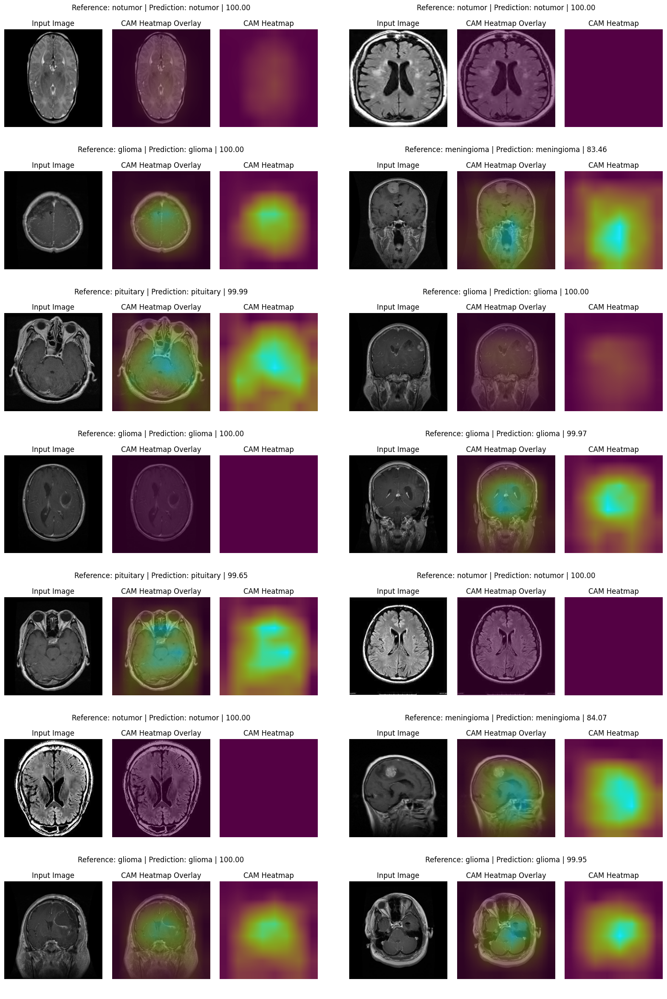

In [ ]:
rows = 7
cols = 2
start = 100

fig = plt.figure(figsize=(20, 30))
outer = gridspec.GridSpec(rows, cols, wspace=0.1, hspace=0.1)

for id, x_i_path in enumerate(x_test[start:start + rows * cols]):
    # Read and preprocess image
    try:
        # Try TIFF first (if some images are .tif)
        x_i_orig = tifffile.imread(x_i_path)
    except Exception:
        img = Image.open(x_i_path).convert("RGB")
        img = img.resize((256, 256))
        x_i_orig = np.array(img)

    x_i = np.expand_dims(x_i_orig, axis=0)
    x_i = x_i.astype("float")
    x_i = preprocess_input(x_i)  # ResNet-specific preprocessing

    # Prediction
    preds = resnet_model.predict(x_i, verbose=0)
    probs = preds[0].max()
    id_class_pred = np.argmax(preds[0])
    str_class_pred = list(classes_dict.keys())[id_class_pred]
    str_class_ref = list(classes_dict.keys())[y_test[start + id]]

    # GradCAM
    cam = GradCAM(resnet_model, id_class_pred)
    heatmap = cam.compute_heatmap(x_i)
    (heatmap, output) = cam.overlay_heatmap(heatmap, x_i_orig, alpha=0.5)

    # Plot
    inner = gridspec.GridSpecFromSubplotSpec(1, 3, subplot_spec=outer[id], wspace=0.1, hspace=0.1)
    ax = plt.Subplot(fig, outer[id])
    ax.set_title("Reference: {} | Prediction: {} | {:.2f}".format(
        str_class_ref, str_class_pred, 100 * probs))
    ax.axis("off")
    fig.add_subplot(ax)

    ax1 = plt.Subplot(fig, inner[0])
    ax1.imshow(x_i_orig.astype("uint8"))
    ax1.axis("off")
    ax1.set_title("Input Image")
    fig.add_subplot(ax1)

    ax2 = plt.Subplot(fig, inner[1])
    ax2.imshow(output)
    ax2.axis("off")
    ax2.set_title("CAM Heatmap Overlay")
    fig.add_subplot(ax2)

    ax3 = plt.Subplot(fig, inner[2])
    ax3.imshow(heatmap)
    ax3.axis("off")
    ax3.set_title("CAM Heatmap")
    fig.add_subplot(ax3)

fig.show()

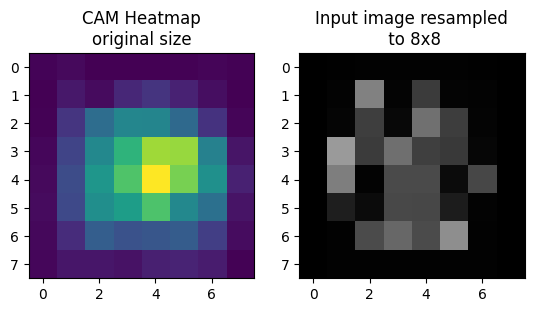

In [ ]:
cam_npy = cam.cam.numpy()

plt.figure()
plt.subplot(121)
plt.imshow(cam_npy)
plt.title("CAM Heatmap\noriginal size")

plt.subplot(122)
plt.imshow(cv2.resize(x_i_orig,cam_npy.shape))
plt.title("Input image resampled\n to 8x8")

plt.show()

### 4.3.2 Training History

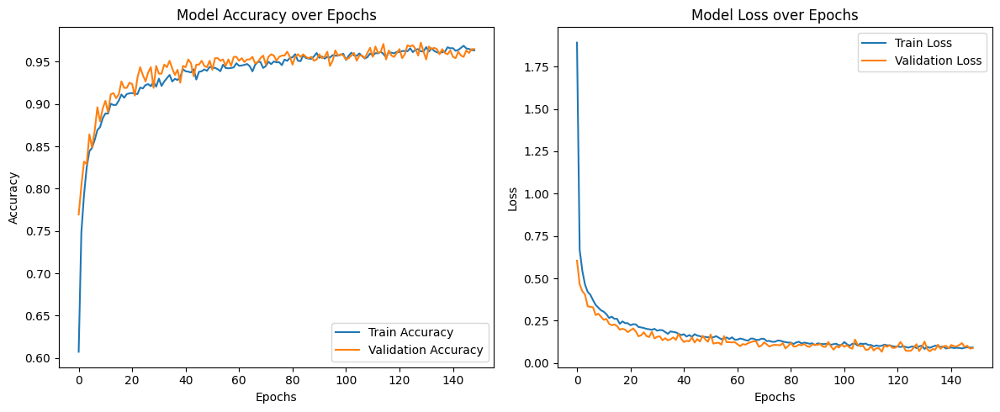

In [ ]:
def plot_training_history(history_path: str):

    # Loading saved history
    with open(history_path, "r") as f:
        history_dict = json.load(f)

    plt.figure(figsize=(12, 5))

    # Accuracy plot
    plt.subplot(1, 2, 1)
    plt.plot(history_dict["accuracy"], label="Train Accuracy")
    plt.plot(history_dict["val_accuracy"], label="Validation Accuracy")
    plt.title("Model Accuracy over Epochs")
    plt.xlabel("Epochs")
    plt.ylabel("Accuracy")
    plt.legend()

    # Loss plot
    plt.subplot(1, 2, 2)
    plt.plot(history_dict["loss"], label="Train Loss")
    plt.plot(history_dict["val_loss"], label="Validation Loss")
    plt.title("Model Loss over Epochs")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.legend()

    plt.tight_layout()
    plt.show()

plot_training_history("resnet50_history.json")


### 4.3.3 Metric Evaluation

In [ ]:
def evaluate_model(model,
                   x_test,
                   y_test,
                   classes_dict,
                   input_size=(256, 256),
                   preprocess_fn=preprocess_input):

    y_pred = []

    for i, img_path in enumerate(x_test):
        # Load image (tiff or other formats)
        try:
            img = tifffile.imread(img_path)
        except Exception:
            img = Image.open(img_path).convert("RGB")
            img = img.resize(input_size)
            img = np.array(img)

        x = np.expand_dims(img, axis=0).astype("float")
        x = preprocess_fn(x)

        preds = model.predict(x, verbose=0)
        y_pred.append(np.argmax(preds[0]))

    idx_to_class = {v: k for k, v in classes_dict.items()}
    target_names = [idx_to_class[i] for i in sorted(idx_to_class)]

    # Classification report
    print("Classification Report:\n")
    print(classification_report(y_test, y_pred, target_names=target_names))

    # Confusion matrix
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=target_names, yticklabels=target_names)
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.title("Confusion Matrix")
    plt.show()

    return y_pred

Classification Report:

              precision    recall  f1-score   support

      glioma       0.94      0.93      0.94       150
  meningioma       0.93      0.93      0.93       153
     notumor       0.99      1.00      1.00       203
   pituitary       0.98      0.98      0.98       150

    accuracy                           0.96       656
   macro avg       0.96      0.96      0.96       656
weighted avg       0.96      0.96      0.96       656



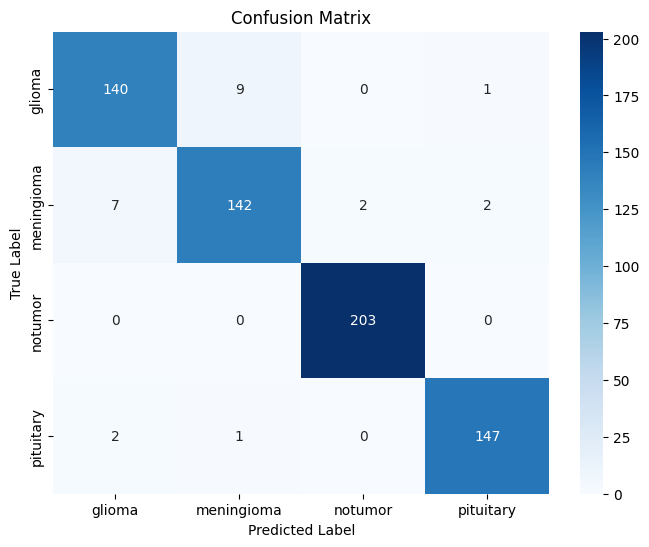

In [ ]:
y_pred_resnet = evaluate_model(resnet_model, x_test, y_test, classes_dict)

#5. DenseNet-121

## 5.1 Model Definition

In [ ]:
def get_densenet_model(n_classes, input_shape):
    base_model = DenseNet121(include_top=False,
                             weights="imagenet",
                             input_shape=input_shape,
                             pooling='max')
    base_model.trainable = False

    x = base_model.output
    x = Flatten()(x)
    x = Dropout(rate=0.3)(x)
    x = Dense(128, activation='relu')(x)
    x = Dropout(rate=0.25)(x)
    output = Dense(n_classes, activation='softmax')(x)

    model = Model(inputs=base_model.input, outputs=output)

    model.compile(optimizer=Adamax(learning_rate=0.001),
                  loss='categorical_crossentropy',
                  metrics=['accuracy', Precision(), Recall()])

    return model

In [ ]:
densenet_model = get_densenet_model(n_classes=n_classes,input_shape=(TARGET_SIZE, TARGET_SIZE, 3))

densenet_model.summary()


29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_15"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding2d      │ (None, 262, 262,  │          0 │ input_layer_1[0]… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 128, 128,  │      9,408 │ zero_padding2d[0… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 128, 128,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 128, 128,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding2d_1    │ (None, 130, 130,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1               │ (None, 64, 64,    │          0 │ zero_padding2d_1… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 64, 64,    │        256 │ pool1[0][0]       │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_relu │ (None, 64, 64,    │          0 │ conv2_block1_0_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 64, 64,    │      8,192 │ conv2_block1_0_r… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 64, 64,    │        512 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 64, 64,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 64, 64,    │     36,864 │ conv2_block1_1_r… │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_concat │ (None, 64, 64,    │          0 │ pool1[0][0],      │
│ (Concatenate)       │ 96)               │            │ conv2_block1_2_c… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_0_bn   │ (None, 64, 64,    │        384 │ conv2_block1_con… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_0_relu │ (None, 64, 64,    │          0 │ conv2_block2_0_b… │
│ (Activation)        │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_1_conv │ (None, 64, 64,    │     12,288 │ conv2_block2_0_r

 Total params: 7,169,220 (27.35 MB)

 Trainable params: 131,716 (514.52 KB)

 Non-trainable params: 7,037,504 (26.85 MB)

In [ ]:
# Callbacks

# Checkpoints
autosave = ModelCheckpoint("densenet_model.keras",
                           mode="max",
                           save_best_only=True,
                           monitor="val_accuracy",
                           verbose=1)

# Early
early_stop = EarlyStopping(patience=10,
                           verbose=1,
                           mode="max",
                           monitor="val_accuracy",
                           restore_best_weights=True)

# Change the index of the data generator to visualize other batch during training
cbks = [autosave,
        early_stop,
        PlotGradCAM(data=data_gen_train[1],
                    n_images=9)
        ]

## 5.2 Model Training

In [ ]:
MODEL_PATH = "densenet_model.keras"
HISTORY_PATH = "densenet121_history.json"

if os.path.exists(MODEL_PATH) and os.path.exists(HISTORY_PATH):
    print("Loading DenseNet121 model and training history from drive:")
    densenet_model = load_model(MODEL_PATH)

    with open(HISTORY_PATH, "r") as f:
        history_dict = json.load(f)

    # Create dummy History object
    history = type("History", (), {})()
    history.history = history_dict

else:
    print("Training new DenseNet121 model:")
    densenet_model = get_densenet_model(n_classes=n_classes,
                                        input_shape=(TARGET_SIZE, TARGET_SIZE, 3))

    history = densenet_model.fit(data_gen_train,
                                 epochs=EPOCHS,
                                 validation_data=data_gen_val,
                                 callbacks=cbks)

    # Save training history to JSON
    history_json = {k: [float(x) for x in v] for k, v in history.history.items()}

    with open(HISTORY_PATH, "w") as f:
        json.dump(history_json, f)

    # Save the trained model
    densenet_model.save(MODEL_PATH)


Loading DenseNet121 model and training history from drive:


## 5.3 Model Evaluation

### 5.3.1 GradCam

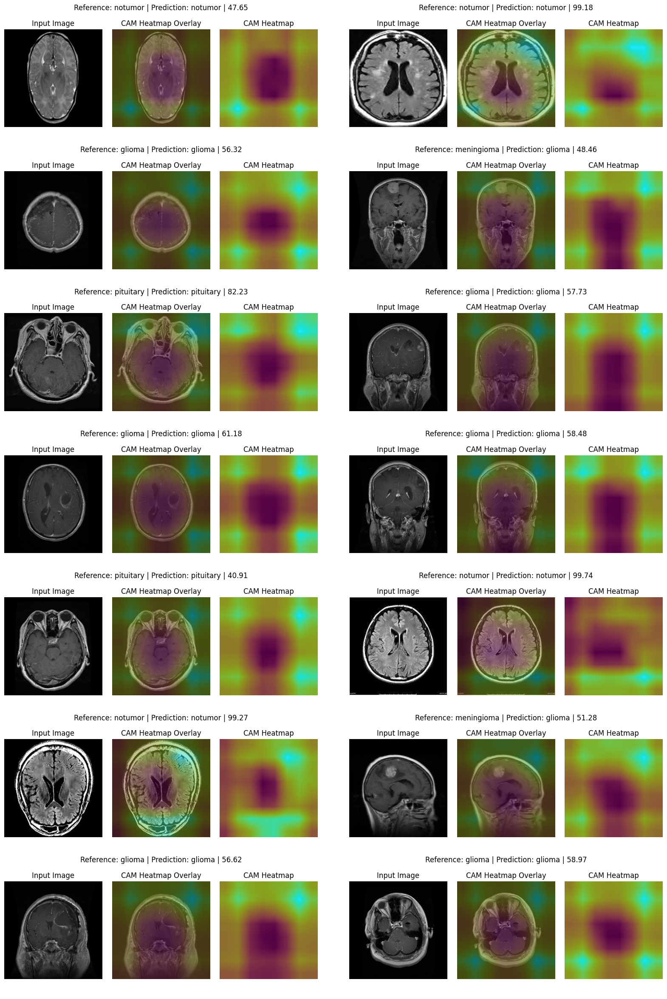

In [ ]:
rows = 7
cols = 2
start = 100

fig = plt.figure(figsize=(20, 30))
outer = gridspec.GridSpec(rows, cols, wspace=0.1, hspace=0.1)

for id, x_i_path in enumerate(x_test[start:start + rows * cols]):
    # Read and preprocess image
    try:
        # Try TIFF first (if some images are .tif)
        x_i_orig = tifffile.imread(x_i_path)
    except Exception:
        img = Image.open(x_i_path).convert("RGB")
        img = img.resize((256, 256))
        x_i_orig = np.array(img)

    x_i = np.expand_dims(x_i_orig, axis=0)
    x_i = x_i.astype("float")
    x_i = preprocess_input(x_i)

    # Prediction
    preds = densenet_model.predict(x_i, verbose=0)
    probs = preds[0].max()
    id_class_pred = np.argmax(preds[0])
    str_class_pred = list(classes_dict.keys())[id_class_pred]
    str_class_ref = list(classes_dict.keys())[y_test[start + id]]

    # GradCAM
    cam = GradCAM(densenet_model, id_class_pred)
    heatmap = cam.compute_heatmap(x_i)
    (heatmap, output) = cam.overlay_heatmap(heatmap, x_i_orig, alpha=0.5)

    # Plot
    inner = gridspec.GridSpecFromSubplotSpec(1, 3, subplot_spec=outer[id], wspace=0.1, hspace=0.1)
    ax = plt.Subplot(fig, outer[id])
    ax.set_title("Reference: {} | Prediction: {} | {:.2f}".format(
        str_class_ref, str_class_pred, 100 * probs))
    ax.axis("off")
    fig.add_subplot(ax)

    ax1 = plt.Subplot(fig, inner[0])
    ax1.imshow(x_i_orig.astype("uint8"))
    ax1.axis("off")
    ax1.set_title("Input Image")
    fig.add_subplot(ax1)

    ax2 = plt.Subplot(fig, inner[1])
    ax2.imshow(output)
    ax2.axis("off")
    ax2.set_title("CAM Heatmap Overlay")
    fig.add_subplot(ax2)

    ax3 = plt.Subplot(fig, inner[2])
    ax3.imshow(heatmap)
    ax3.axis("off")
    ax3.set_title("CAM Heatmap")
    fig.add_subplot(ax3)

fig.show()

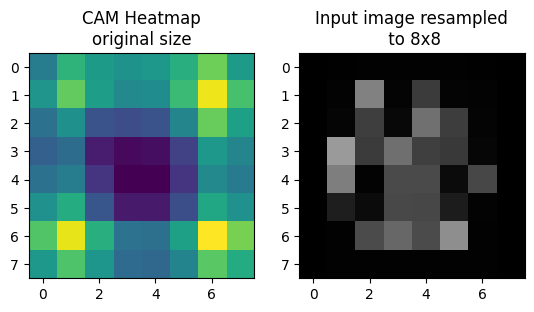

In [ ]:
cam_npy = cam.cam.numpy()

plt.figure()
plt.subplot(121)
plt.imshow(cam_npy)
plt.title("CAM Heatmap\noriginal size")

plt.subplot(122)
plt.imshow(cv2.resize(x_i_orig,cam_npy.shape))
plt.title("Input image resampled\n to 8x8")

plt.show()

### 5.3.2 Training History

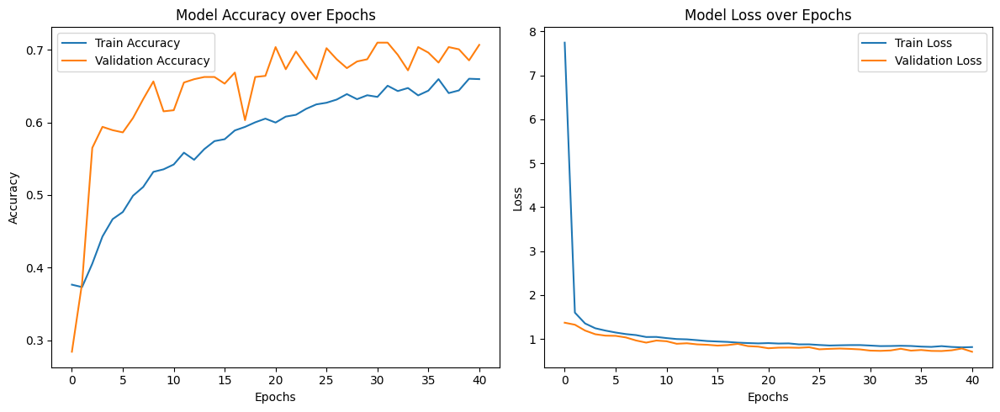

In [ ]:
plot_training_history("densenet121_history.json")

### 5.3.3 Metric Evaluation

Classification Report:

              precision    recall  f1-score   support

      glioma       0.63      0.83      0.72       150
  meningioma       0.55      0.19      0.28       153
     notumor       0.79      0.91      0.85       203
   pituitary       0.75      0.87      0.81       150

    accuracy                           0.71       656
   macro avg       0.68      0.70      0.66       656
weighted avg       0.69      0.71      0.68       656



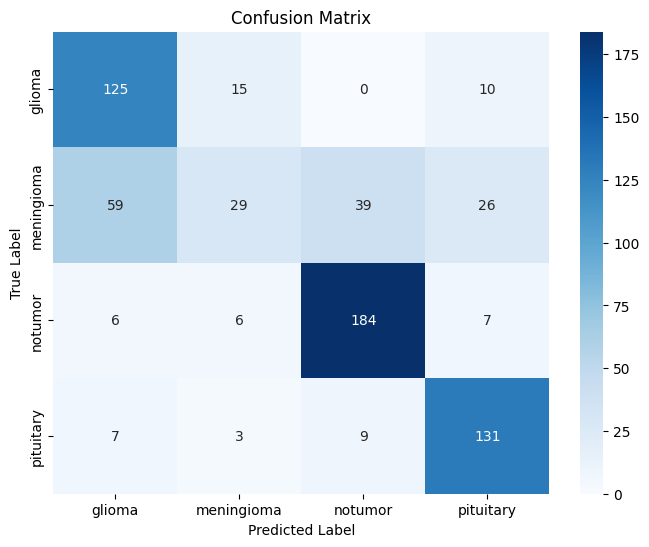

In [ ]:
y_pred_densenet = evaluate_model(densenet_model, x_test, y_test, classes_dict)

# 6. MobileNet-V2

## 6.1 Model Definition

In [ ]:
def get_mobilenet_model(n_classes, input_shape, fine_tune_at=None):


    base_model = MobileNetV2(include_top=False,
                             weights='imagenet',
                             input_shape=input_shape,
                             pooling=None)

    base_model.trainable = False

    x = base_model.output
    x = GlobalAveragePooling2D()(x)
    x = BatchNormalization()(x)
    x = Dropout(0.3)(x)
    x = Dense(256, activation='relu')(x)
    x = BatchNormalization()(x)
    x = Dropout(0.25)(x)
    x = Dense(128, activation='relu')(x)
    x = BatchNormalization()(x)
    x = Dropout(0.2)(x)

    output = Dense(n_classes, activation='softmax')(x)

    model = Model(inputs=base_model.input, outputs=output)

    model.compile(optimizer=Adam(learning_rate=1e-4),
                  loss='categorical_crossentropy',
                  metrics=['accuracy', Precision(name='precision'), Recall(name='recall')])

    return model


In [ ]:
mobilenet_model = get_mobilenet_model(n_classes=n_classes,
                                input_shape=(TARGET_SIZE, TARGET_SIZE, 3))

mobilenet_model.summary()

/tmp/ipython-input-3132386262.py:4: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = MobileNetV2(include_top=False,


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_30"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 128, 128,  │        864 │ input_layer_2[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 128, 128,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 128, 128,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 128, 128,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 128, 128,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 128, 128,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 128, 128,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 128, 128,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 128, 128,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 128, 128,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 128, 128,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 129, 129,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 64, 64,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 64, 64,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 64, 64,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 64, 64,    │      2,304 │ block_1_depthwis

 Total params: 2,625,988 (10.02 MB)

 Trainable params: 364,676 (1.39 MB)

 Non-trainable params: 2,261,312 (8.63 MB)

In [ ]:
# Callbacks

# Checkpoints
autosave = ModelCheckpoint("mobilenet_model.keras",
                           mode="max",
                           save_best_only=True,
                           monitor="val_accuracy",
                           verbose=1)

# Early stopping
early_stop = EarlyStopping(patience=10,
                           verbose=1,
                           mode="max",
                           monitor="val_accuracy",
                           restore_best_weights=True)

# Change the index of the data generator to visualize other batch during training
cbks = [autosave,
        early_stop,
        PlotGradCAM(data=data_gen_train[1],
                    n_images=9)
        ]

## 6.2 Model Training

In [ ]:
# Cell 5: Train or Load MobileNetV2 model
MODEL_PATH = "mobilenet_model.keras"
HISTORY_PATH = "mobilenet_history.json"

if os.path.exists(MODEL_PATH) and os.path.exists(HISTORY_PATH):
    print("Loading MobileNetV2 model and training history from drive:")
    mobilenet_model = load_model(MODEL_PATH)

    with open(HISTORY_PATH, "r") as f:
        history_dict = json.load(f)

    # Create a dummy object to mimic Keras History
    history = type("History", (), {})()
    history.history = history_dict

else:
    print("Training new MobileNetV2 model:")
    mobilenet_model = get_mobilenet_model(
        n_classes=n_classes,
        input_shape=(TARGET_SIZE, TARGET_SIZE, 3)
    )

    history = mobilenet_model.fit(
        data_gen_train,
        epochs=EPOCHS,
        validation_data=data_gen_val,
        callbacks=cbks
    )

    # Ensure JSON-safe conversion
    history_json = {k: [float(x) for x in v] for k, v in history.history.items()}

    with open(HISTORY_PATH, "w") as f:
        json.dump(history_json, f)

Loading MobileNetV2 model and training history from drive:


## 6.3 Model Evaluation

### 6.3.1 GradCam

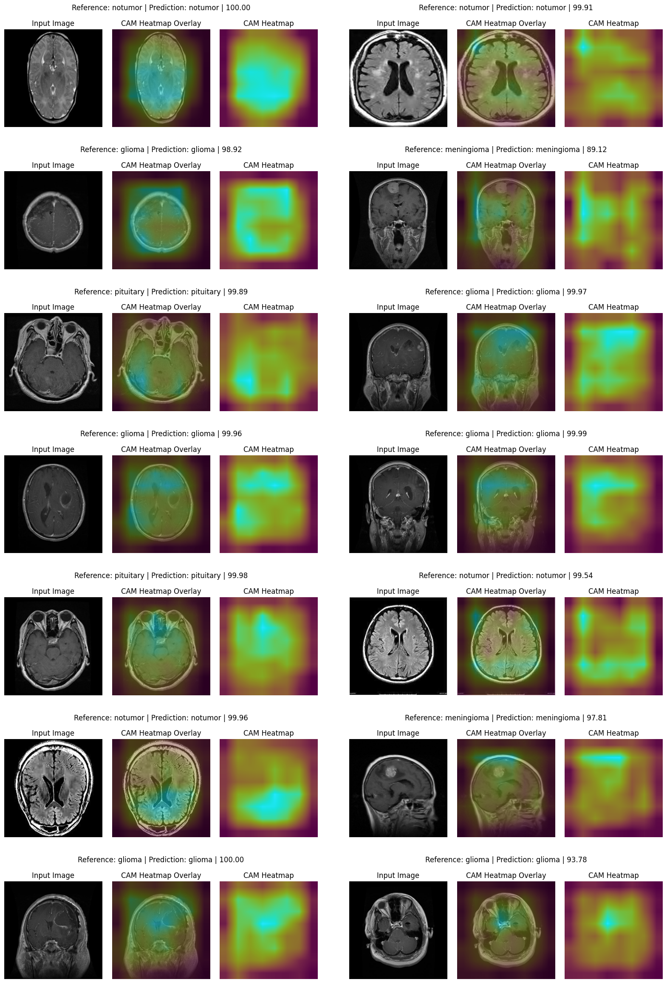

In [ ]:
rows = 7
cols = 2
start = 100

fig = plt.figure(figsize=(20, 30))
outer = gridspec.GridSpec(rows, cols, wspace=0.1, hspace=0.1)

for id, x_i_path in enumerate(x_test[start:start + rows * cols]):
    # Read and preprocess image
    try:
        # Try TIFF first (if some images are .tif)
        x_i_orig = tifffile.imread(x_i_path)
    except Exception:
        img = Image.open(x_i_path).convert("RGB")
        img = img.resize((256, 256))
        x_i_orig = np.array(img)

    x_i = np.expand_dims(x_i_orig, axis=0)
    x_i = x_i.astype("float")
    x_i = preprocess_input(x_i)

    # Prediction
    preds = mobilenet_model.predict(x_i, verbose=0)
    probs = preds[0].max()
    id_class_pred = np.argmax(preds[0])
    str_class_pred = list(classes_dict.keys())[id_class_pred]
    str_class_ref = list(classes_dict.keys())[y_test[start + id]]

    # GradCAM
    cam = GradCAM(mobilenet_model, id_class_pred)
    heatmap = cam.compute_heatmap(x_i)
    (heatmap, output) = cam.overlay_heatmap(heatmap, x_i_orig, alpha=0.5)

    # Plot
    inner = gridspec.GridSpecFromSubplotSpec(1, 3, subplot_spec=outer[id], wspace=0.1, hspace=0.1)
    ax = plt.Subplot(fig, outer[id])
    ax.set_title("Reference: {} | Prediction: {} | {:.2f}".format(
        str_class_ref, str_class_pred, 100 * probs))
    ax.axis("off")
    fig.add_subplot(ax)

    ax1 = plt.Subplot(fig, inner[0])
    ax1.imshow(x_i_orig.astype("uint8"))
    ax1.axis("off")
    ax1.set_title("Input Image")
    fig.add_subplot(ax1)

    ax2 = plt.Subplot(fig, inner[1])
    ax2.imshow(output)
    ax2.axis("off")
    ax2.set_title("CAM Heatmap Overlay")
    fig.add_subplot(ax2)

    ax3 = plt.Subplot(fig, inner[2])
    ax3.imshow(heatmap)
    ax3.axis("off")
    ax3.set_title("CAM Heatmap")
    fig.add_subplot(ax3)

fig.show()

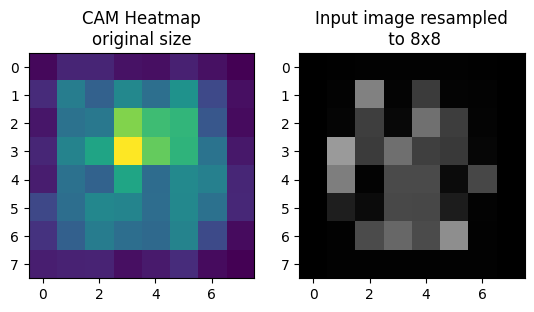

In [ ]:
cam_npy = cam.cam.numpy()

plt.figure()
plt.subplot(121)
plt.imshow(cam_npy)
plt.title("CAM Heatmap\noriginal size")

plt.subplot(122)
plt.imshow(cv2.resize(x_i_orig,cam_npy.shape))
plt.title("Input image resampled\n to 8x8")

plt.show()

### 6.3.2 Training History

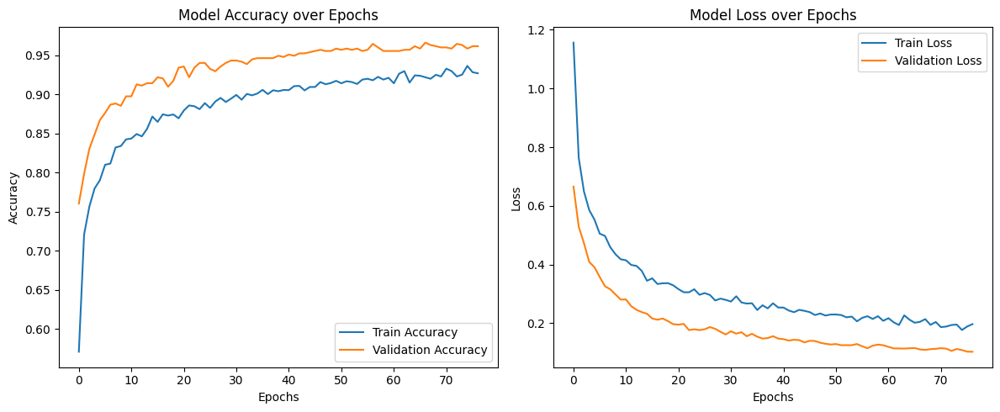

In [ ]:
plot_training_history("mobilenet_history.json")

### 6.3.3 Metric Evaluation

Classification Report:

              precision    recall  f1-score   support

      glioma       0.98      0.91      0.94       150
  meningioma       0.91      0.94      0.93       153
     notumor       0.99      1.00      1.00       203
   pituitary       0.97      0.99      0.98       150

    accuracy                           0.96       656
   macro avg       0.96      0.96      0.96       656
weighted avg       0.96      0.96      0.96       656



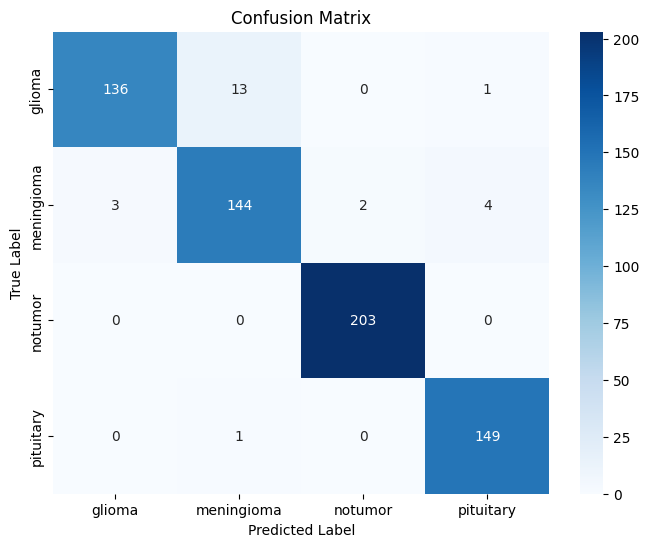

In [ ]:
y_pred_mobilenet = evaluate_model(mobilenet_model, x_test, y_test, classes_dict)

# 7. VGG-16

## 7.1 Model Definition

In [ ]:
def get_vgg_model(n_classes, input_shape):
    base_model = VGG16(include_top=False,
                       weights='imagenet',
                       input_shape=input_shape)

    base_model.trainable = False

    x = base_model.output
    x = GlobalAveragePooling2D()(x)
    x = BatchNormalization()(x)
    x = Dropout(0.4)(x)
    x = Dense(512, activation='relu')(x)

    x = BatchNormalization()(x)
    x = Dropout(0.3)(x)
    x = Dense(256, activation='relu')(x)

    x = BatchNormalization()(x)
    x = Dropout(0.2)(x)
    x = Dense(128, activation='relu')(x)

    x = BatchNormalization()(x)
    x = Dropout(0.1)(x)

    output = Dense(n_classes, activation='softmax')(x)

    model = Model(inputs=base_model.input, outputs=output)

    model.compile(optimizer=Adam(learning_rate=1e-4),
                  loss='categorical_crossentropy',
                  metrics=['accuracy', Precision(name='precision'), Recall(name='recall')])

    return model


In [ ]:
vgg16_model = get_vgg_model(n_classes=n_classes,
                                input_shape=(TARGET_SIZE, TARGET_SIZE, 3))

vgg16_model.summary()

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_45"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 256, 256, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 256, 256, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 128, 128, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 128, 128, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 128, 128, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 64, 64, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 64, 64, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 64, 64, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 64, 64, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 32, 32, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 32, 32, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 32, 32, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 32, 32, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 16, 16, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 16, 16, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 16, 16, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 16, 16, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 8, 8, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 512)            │         2,04

 Total params: 15,147,716 (57.78 MB)

 Trainable params: 430,212 (1.64 MB)

 Non-trainable params: 14,717,504 (56.14 MB)

In [ ]:
# Callbacks

# Checkpoints
autosave = ModelCheckpoint("vgg16_model.keras",
                           mode="max",
                           save_best_only=True,
                           monitor="val_accuracy",
                           verbose=1)

# Early stopping
early_stop = EarlyStopping(patience=10,
                           verbose=1,
                           mode="max",
                           monitor="val_accuracy",
                           restore_best_weights=True)

# Change the index of the data generator to visualize other batch during training
cbks = [autosave,
        early_stop,
        PlotGradCAM(data=data_gen_train[1],
                    n_images=9)
        ]

## 7.2 Model Training

In [ ]:
MODEL_PATH = "vgg16_model.keras"
HISTORY_PATH = "vgg16_history.json"

if os.path.exists(MODEL_PATH) and os.path.exists(HISTORY_PATH):
    print("Loading VGG16 model and training history from drive:")
    vgg16_model = load_model(MODEL_PATH)

    with open(HISTORY_PATH, "r") as f:
        history_dict = json.load(f)

    history = type("History", (), {})()
    history.history = history_dict

else:
    print("Training new VGG16 model:")
    vgg16_model = get_vgg_model(
        n_classes=n_classes,
        input_shape=(TARGET_SIZE, TARGET_SIZE, 3)
    )

    history = vgg16_model.fit(
        data_gen_train,
        epochs=EPOCHS,
        validation_data=data_gen_val,
        callbacks=cbks
    )

    history_json = {k: [float(x) for x in v] for k, v in history.history.items()}

    with open(HISTORY_PATH, "w") as f:
        json.dump(history_json, f)

Loading VGG16 model and training history from drive:


## 7.3 Metric Evaluation

### 7.3.1 GradCam

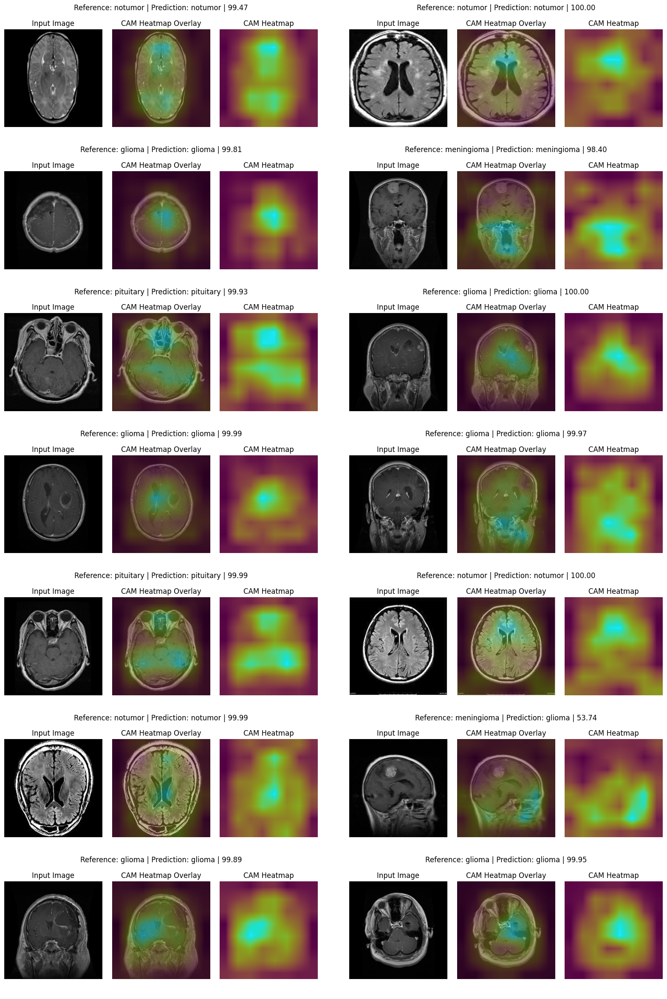

In [ ]:
rows = 7
cols = 2
start = 100

fig = plt.figure(figsize=(20, 30))
outer = gridspec.GridSpec(rows, cols, wspace=0.1, hspace=0.1)

for id, x_i_path in enumerate(x_test[start:start + rows * cols]):
    # Read and preprocess image
    try:
        # Try TIFF first (if some images are .tif)
        x_i_orig = tifffile.imread(x_i_path)
    except Exception:
        img = Image.open(x_i_path).convert("RGB")
        img = img.resize((256, 256))
        x_i_orig = np.array(img)

    x_i = np.expand_dims(x_i_orig, axis=0)
    x_i = x_i.astype("float")
    x_i = preprocess_input(x_i)

    # Prediction
    preds = vgg16_model.predict(x_i, verbose=0)
    probs = preds[0].max()
    id_class_pred = np.argmax(preds[0])
    str_class_pred = list(classes_dict.keys())[id_class_pred]
    str_class_ref = list(classes_dict.keys())[y_test[start + id]]

    # GradCAM
    cam = GradCAM(vgg16_model, id_class_pred)
    heatmap = cam.compute_heatmap(x_i)
    (heatmap, output) = cam.overlay_heatmap(heatmap, x_i_orig, alpha=0.5)

    # Plot
    inner = gridspec.GridSpecFromSubplotSpec(1, 3, subplot_spec=outer[id], wspace=0.1, hspace=0.1)
    ax = plt.Subplot(fig, outer[id])
    ax.set_title("Reference: {} | Prediction: {} | {:.2f}".format(
        str_class_ref, str_class_pred, 100 * probs))
    ax.axis("off")
    fig.add_subplot(ax)

    ax1 = plt.Subplot(fig, inner[0])
    ax1.imshow(x_i_orig.astype("uint8"))
    ax1.axis("off")
    ax1.set_title("Input Image")
    fig.add_subplot(ax1)

    ax2 = plt.Subplot(fig, inner[1])
    ax2.imshow(output)
    ax2.axis("off")
    ax2.set_title("CAM Heatmap Overlay")
    fig.add_subplot(ax2)

    ax3 = plt.Subplot(fig, inner[2])
    ax3.imshow(heatmap)
    ax3.axis("off")
    ax3.set_title("CAM Heatmap")
    fig.add_subplot(ax3)

fig.show()

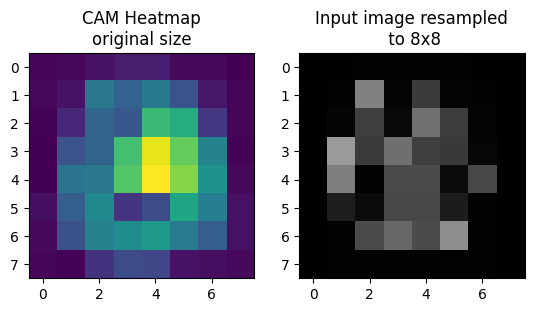

In [ ]:
cam_npy = cam.cam.numpy()

plt.figure()
plt.subplot(121)
plt.imshow(cam_npy)
plt.title("CAM Heatmap\noriginal size")

plt.subplot(122)
plt.imshow(cv2.resize(x_i_orig,cam_npy.shape))
plt.title("Input image resampled\n to 8x8")

plt.show()

### 7.3.2 Training History

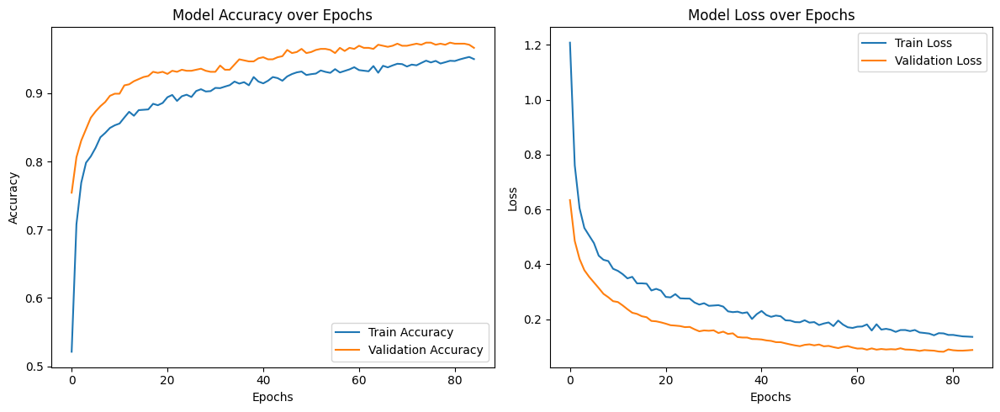

In [ ]:
plot_training_history("vgg16_history.json")

### 7.3.3 Metric Evaluation

Classification Report:

              precision    recall  f1-score   support

      glioma       0.96      0.91      0.93       150
  meningioma       0.90      0.95      0.92       153
     notumor       1.00      1.00      1.00       203
   pituitary       0.99      0.99      0.99       150

    accuracy                           0.96       656
   macro avg       0.96      0.96      0.96       656
weighted avg       0.96      0.96      0.96       656



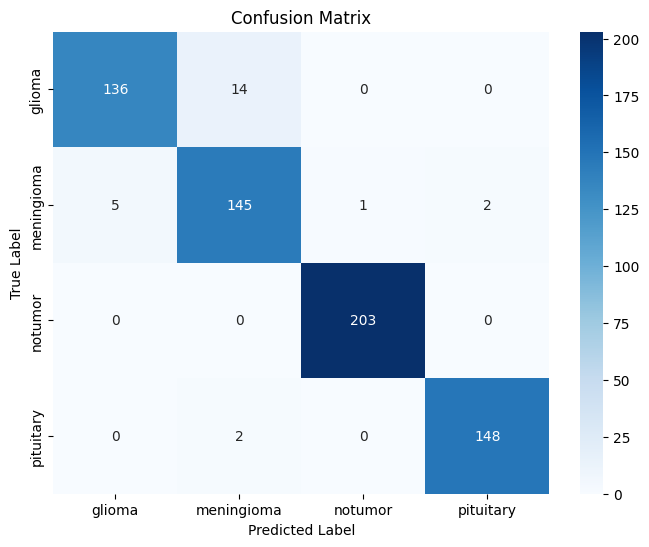

In [ ]:
y_pred_vgg = evaluate_model(vgg16_model, x_test, y_test, classes_dict)

#8. Results

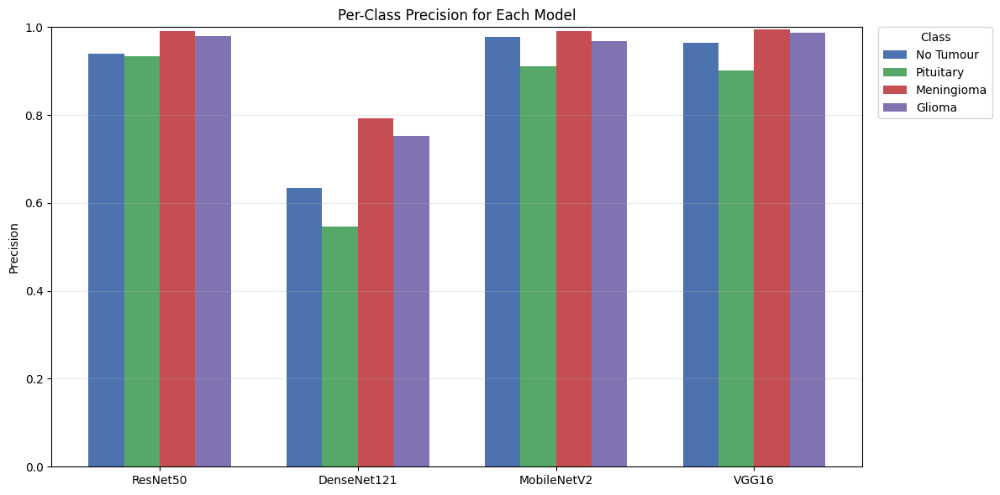

In [ ]:
def plot_precision_grouped_bar(precision_dict):

    models = list(precision_dict.keys())
    classes = ['No Tumour','Pituitary','Meningioma','Glioma']
    colors = ['#4C72B0', '#55A868', '#C44E52', '#8172B2']


    data = np.array(list(precision_dict.values()))

    x = np.arange(len(models))
    width = 0.18

    fig, ax = plt.subplots(figsize=(12, 6))

    for i, class_name in enumerate(classes):
        ax.bar(x + i*width, data[:, i], width,
               label=class_name, color=colors[i])

    ax.set_ylabel('Precision')
    ax.set_title('Per-Class Precision for Each Model')
    ax.set_xticks(x + 1.5*width)
    ax.set_xticklabels(models)
    ax.set_ylim(0, 1)
    ax.legend(title='Class', bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)
    ax.grid(axis='y', alpha=0.3)

    plt.tight_layout()
    plt.show()


def precision_per_class(y_true, y_pred):
  classes = ['notumour','pituitary','meningioma','glioma']
  rep = classification_report(
        y_true, y_pred,
        target_names=classes,
        output_dict=True
    )
  return [rep[c]['precision'] for c in classes]


precision_values = {
    "ResNet50":    precision_per_class(y_test, y_pred_resnet),
    "DenseNet121": precision_per_class(y_test, y_pred_densenet),
    "MobileNetV2": precision_per_class(y_test, y_pred_mobilenet),
    "VGG16":       precision_per_class(y_test, y_pred_vgg)
}


plot_precision_grouped_bar(precision_values)